# Lending pass-through event study

Table 3.5.

In [1]:
from pathlib import Path
import os

# Locate the bundle from either its root or the notebooks directory.
_here = Path.cwd().resolve()
_ROOT = next((p for p in [_here, *_here.parents]
              if (p / "data").is_dir() and (p / "notebooks").is_dir()), None)
if _ROOT is None:
    raise FileNotFoundError("Open this notebook inside the Tesi_codice_consegna folder.")
_DATA_DIR = _ROOT / "data"
_OUTPUT_DIR = _ROOT / "results" / "rerun" / "04_lending_event_study"
_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
os.chdir(_OUTPUT_DIR)
print("Data:", _DATA_DIR)
print("New outputs:", _OUTPUT_DIR)


Data: /Users/macbook/Desktop/Tesi Master/Tesi_codice_consegna/data
New outputs: /Users/macbook/Desktop/Tesi Master/Tesi_codice_consegna/results/rerun/04_lending_event_study


## Lending and Curve event-window comparison

Original event-study function and calls retained. Added the imports and data loading that previously lived in cell 2; aavecm.csv is byte-identical to the bundled aavegas.csv. The stored lending output matches Table 3.5. The Curve comparison output is retained because it is part of the same source cell, but is not presented as a match for Table 3.2.

Source: `AAVE v2/event(future2y_stable coin).ipynb`, original cell 4 (zero-based).

04_lending_event_study.ipynb:cell3:6: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
04_lending_event_study.ipynb:cell3:7: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.

==================== INIZIO ANALISI (VARIAZIONE TOTALE - MODELLO COMPLETO) PER: LENDING INDEX (AGGREGATE) ====================
Calcolo dei Rendimenti Anomali...
Esecuzione delle regressioni...

--- Risultati (Variazione Totale - Modello Completo) per Lending Index (Aggregate) ---
+-------------+---------------+---------------+----------------+
|   Event Day |   coef_target |   pval_target |   rsquared_adj |
+=============+===============+===============+================+
|          -2 |        0.0000 |        0.5377 |        -0.1184 |
+-------------

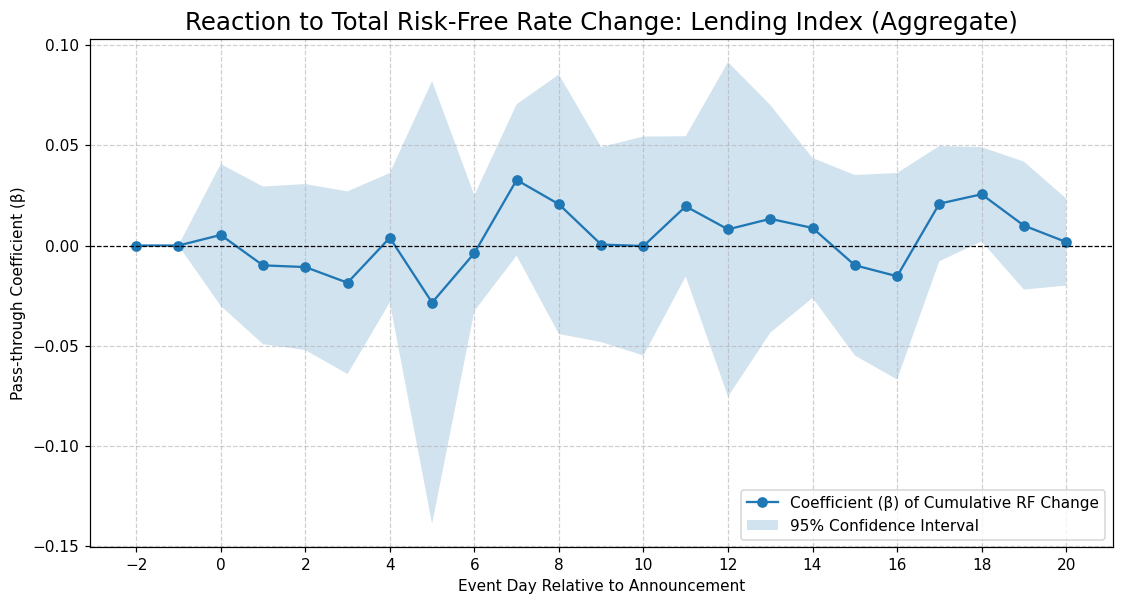

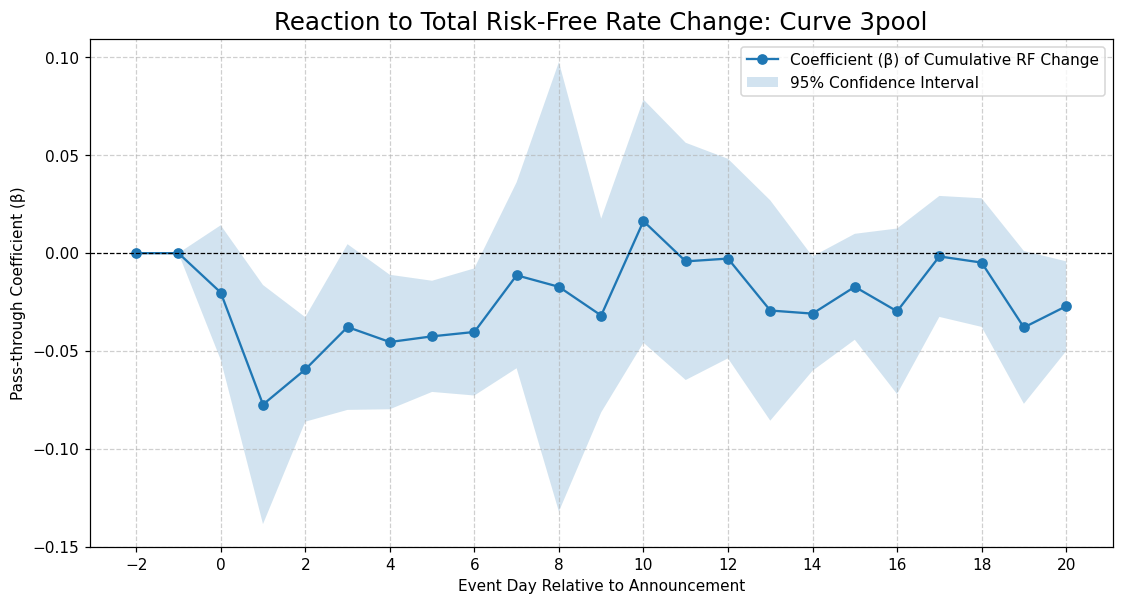

In [2]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt
from tabulate import tabulate
df_main = pd.read_csv(str(_DATA_DIR / 'aavegas.csv'), parse_dates=['date'], dayfirst=True).set_index('date')
df_surprises_main = pd.read_csv(str(_DATA_DIR / 'ABJ-2024.csv'), parse_dates=['date'], dayfirst=True).set_index('date')

def run_event_study_total_change(df_returns, df_surprises, asset_column_name, asset_label, risk_free_col='3m ir'):
    """
    Esegue un event study testando la reazione alla variazione CUMULATA del tasso risk-free,
    controllando per i driver crypto-nativi.
    """
    print(f"\n{'='*20} INIZIO ANALISI (VARIAZIONE TOTALE - MODELLO COMPLETO) PER: {asset_label.upper()} {'='*20}")
    
    # ... (tutta la parte di setup e calcolo AR rimane identica) ...
    estimation_window = 60
    event_window_start = -2
    event_window_end = 20
    event_window_days = np.arange(event_window_start, event_window_end + 1)
    df_merged = df_returns.join(df_surprises, how='inner')
    fomc_dates = df_merged.index
    ar_col_name = f'{asset_column_name}_ar'
    df_returns[ar_col_name] = np.nan
    df_returns.sort_index(inplace=True)
    print("Calcolo dei Rendimenti Anomali...")
    for event_date in fomc_dates:
        try:
            event_date_loc = df_returns.index.get_loc(event_date)
        except KeyError: continue
        estimation_start_loc = event_date_loc + event_window_start - estimation_window
        estimation_end_loc = event_date_loc + event_window_start
        if estimation_start_loc < 0: continue
        estimation_data = df_returns.iloc[estimation_start_loc:estimation_end_loc]
        normal_return = estimation_data[asset_column_name].mean()
        for d in event_window_days:
            current_date_loc = event_date_loc + d
            if 0 <= current_date_loc < len(df_returns):
                current_date = df_returns.index[current_date_loc]
                abnormal_return = df_returns.loc[current_date, asset_column_name] - normal_return
                df_returns.loc[current_date, ar_col_name] = abnormal_return

    print("Esecuzione delle regressioni...")
    results = []
    
    df_returns[f'{risk_free_col}_diff'] = df_returns[risk_free_col].diff()

    for d in event_window_days:
        y_target_dates = fomc_dates + pd.DateOffset(days=d)
        
        valid_ar_data = df_returns.loc[y_target_dates[y_target_dates.isin(df_returns.index)]].dropna(subset=[ar_col_name])
        valid_y_dates = valid_ar_data.index
        
        y_asset = valid_ar_data[ar_col_name]
        
        cumulative_change = []
        for event_date in valid_y_dates - pd.DateOffset(days=d):
            window = df_returns.loc[event_date : event_date + pd.DateOffset(days=d)]
            cum_change = window[f'{risk_free_col}_diff'].sum()
            cumulative_change.append(cum_change)
        
        X = pd.DataFrame({
            'cumulative_rf_change': cumulative_change,
        }, index=valid_y_dates)
        
        control_vars = ['S&P 500', 'ethperpetual', 'gas_fees']
        X_controls = valid_ar_data[control_vars]
        
        X = pd.concat([X, X_controls], axis=1)
        X = sm.add_constant(X)

        if len(y_asset) < X.shape[1] + 1: continue

        model = sm.OLS(y_asset.values, X.values, missing='drop').fit(cov_type='HAC', cov_kwds={'maxlags': 1})
        
        # --- CORREZIONE QUI: Usa indici numerici per accedere ai risultati ---
        results.append({
            'Event Day': d,
            'coef_target': model.params[1],          # Indice 1 per 'cumulative_rf_change'
            'pval_target': model.pvalues[1],
            'rsquared_adj': model.rsquared_adj,
            'ci_lower': model.conf_int()[1][0],
            'ci_upper': model.conf_int()[1][1],
        })
        # --------------------------------------------------------------------

    df_results = pd.DataFrame(results).set_index('Event Day')
    
    # ... (il resto della funzione per stampare e plottare rimane uguale) ...
    print(f"\n--- Risultati (Variazione Totale - Modello Completo) per {asset_label} ---")
    cols_to_print = ['coef_target', 'pval_target', 'rsquared_adj']
    print(tabulate(df_results[cols_to_print], headers='keys', tablefmt='grid', floatfmt=".4f"))
    
    fig, ax = plt.subplots(figsize=(12, 6))
    ax.plot(df_results.index, df_results['coef_target'], marker='o', linestyle='-', label='Coefficient (β) of Cumulative RF Change')
    ax.fill_between(df_results.index, df_results['ci_lower'], df_results['ci_upper'], alpha=0.2, label='95% Confidence Interval')
    ax.axhline(0, color='black', linestyle='--', linewidth=0.8)
    ax.set_title(f'Reaction to Total Risk-Free Rate Change: {asset_label}', fontsize=16)
    ax.set_xlabel('Event Day Relative to Announcement')
    ax.set_ylabel('Pass-through Coefficient (β)')
    ax.grid(True, linestyle='--', alpha=0.6)
    ax.legend()
    plt.xticks(np.arange(min(event_window_days), max(event_window_days)+1, 2))
    plt.show()
# --- ESECUZIONE DELLA NUOVA ANALISI ---

# Esegui per l'indice Aggregato
results_agg_total_change = run_event_study_total_change(df_main.copy(), df_surprises_main, 'stablecoin', 'Lending Index (Aggregate)')

# Esegui per il 3pool (per confronto)
results_3pool_total_change = run_event_study_total_change(df_main.copy(), df_surprises_main, '3pool', 'Curve 3pool')